In [135]:
#Téléchargement du dataset .csv
from google.colab import files
fichier = files.upload()

# **Analyse exploratoire**

L'analyse exploratoire de données (EDA) est une étape essentielle au début du pipeline de Machine Learning (ML). Elle consiste à examiner et résumer les principales caractéristiques d'un jeu de données avant de choisir ou d'entraîner un modèle.
Son objectif est de comprendre la structure des données, de repérer les anomalies et d'orienter les prochaines étapes de préparation.

L'EDA intervient juste après la collecte des données et guide directement le nettoyage et l'ingénierie des caractéristiques (feature engineering).



## 1. Inspection générale
* Dimensions


In [136]:
import pandas as pd


In [137]:
df = pd.read_csv("/content/dataset-titanic-6afac2fa9ddd8043393546.csv")

In [138]:
df.shape

(891, 12)

* Type de variables & Aperçu


In [139]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


## 2. Analyse de la qualité des données

In [140]:
resume = pd.DataFrame({
      "Type": df.dtypes,
      "Valeurs_Manquantes": df.isnull().sum(),
      "Pourcentage_Manquant (%)": (df.isnull().sum() / len(df) * 100).round(2)
  })
print(resume.sort_values(by="Pourcentage_Manquant (%)", ascending=False))
print("\n")

print("=" * 50)
print("STATISTIQUES DESCRIPTIVES")
print("=" * 50)
# Aide à repérer les valeurs aberrantes
print(df.describe().T[["count", "mean", "std", "min", "50%", "max"]])
print("\n")

                Type  Valeurs_Manquantes  Pourcentage_Manquant (%)
Cabin         object                 687                     77.10
Age          float64                 177                     19.87
Embarked      object                   2                      0.22
PassengerId    int64                   0                      0.00
Name          object                   0                      0.00
Pclass         int64                   0                      0.00
Survived       int64                   0                      0.00
Sex           object                   0                      0.00
Parch          int64                   0                      0.00
SibSp          int64                   0                      0.00
Fare         float64                   0                      0.00
Ticket        object                   0                      0.00


STATISTIQUES DESCRIPTIVES
             count        mean         std   min       50%       max
PassengerId  891.0  446.000000  

-- RESULTATS --

• Les colonnes inutiles : Celles qui ont un pourcentage de valeurs manquantes trop élevé (ex. > 80 %) :

**Age ?, Cabin ?**

• Les erreurs de typage : Une colonne de dates ou de nombres lue comme du texte (object) à cause d'un caractère spécial caché :

**Embarked, Name, Sex, Ticket**

##  3. Analyse univariée

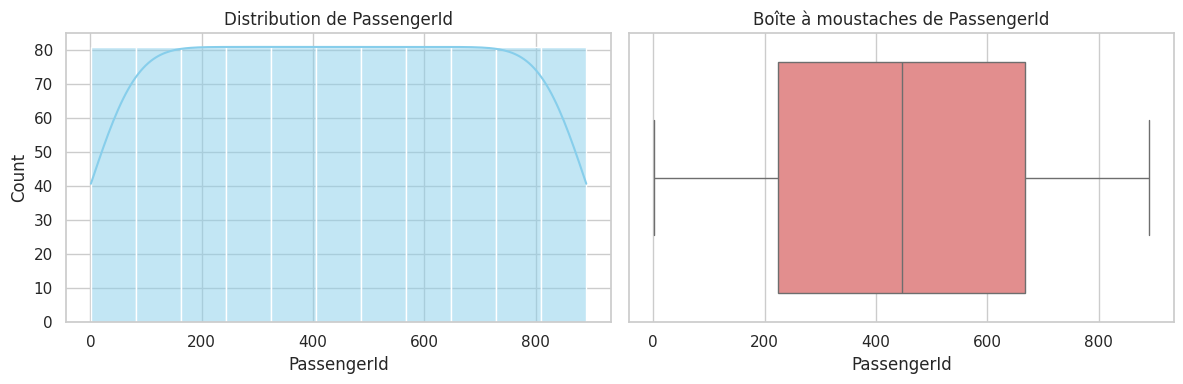

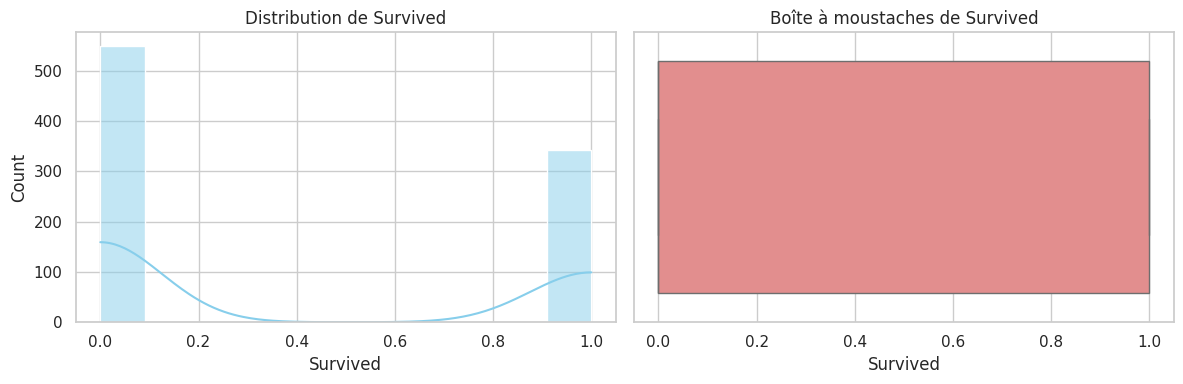

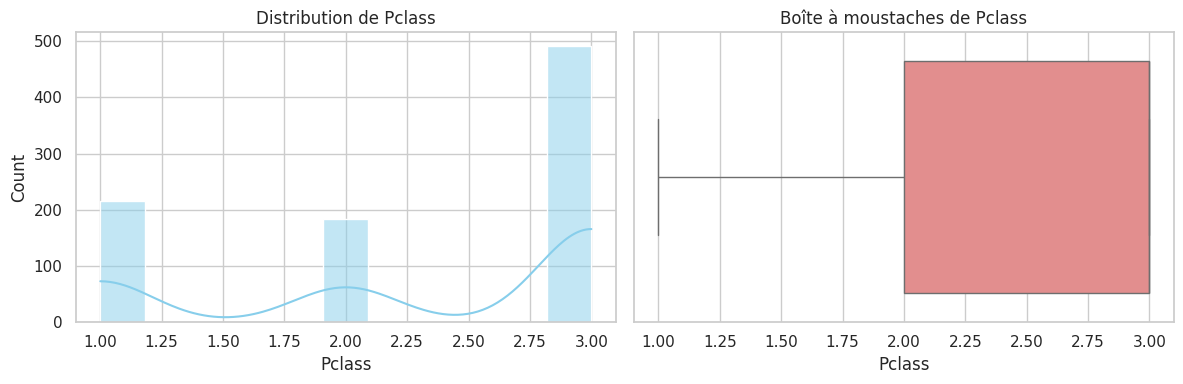

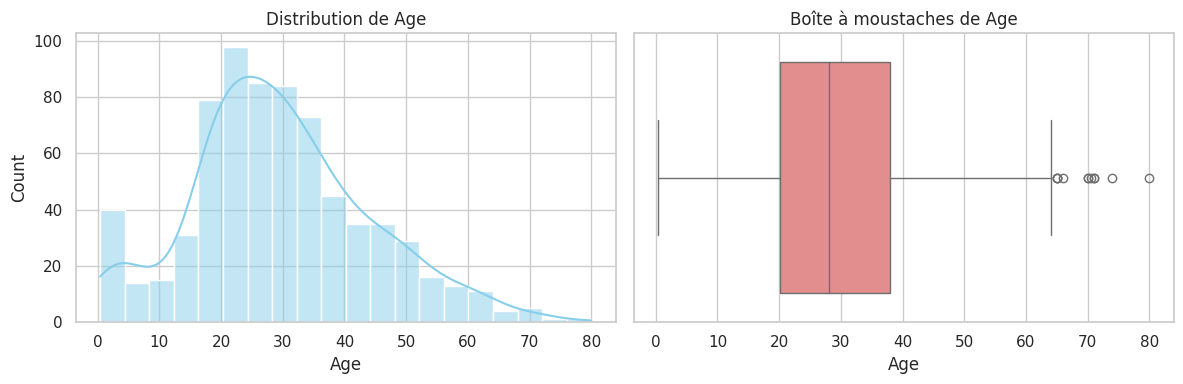

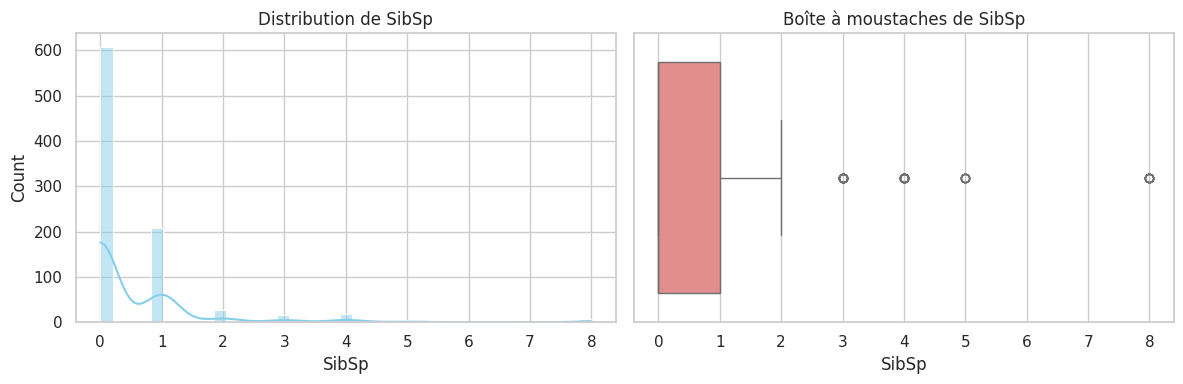

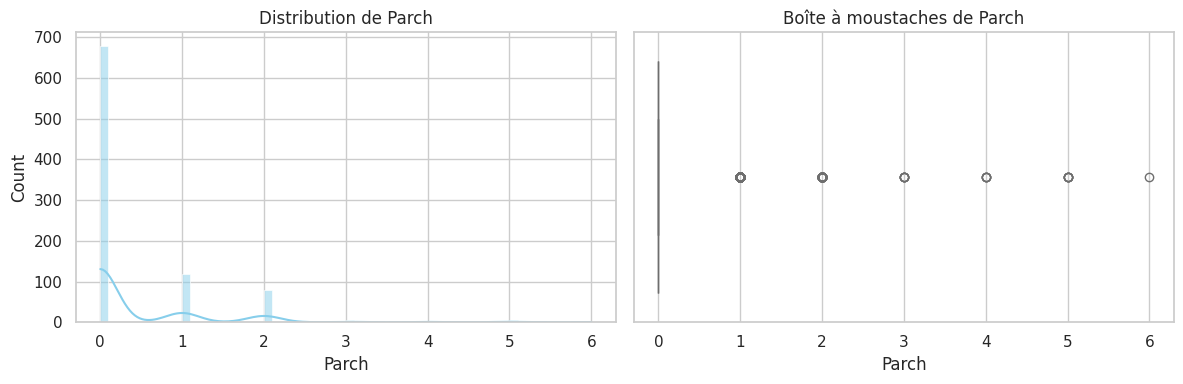

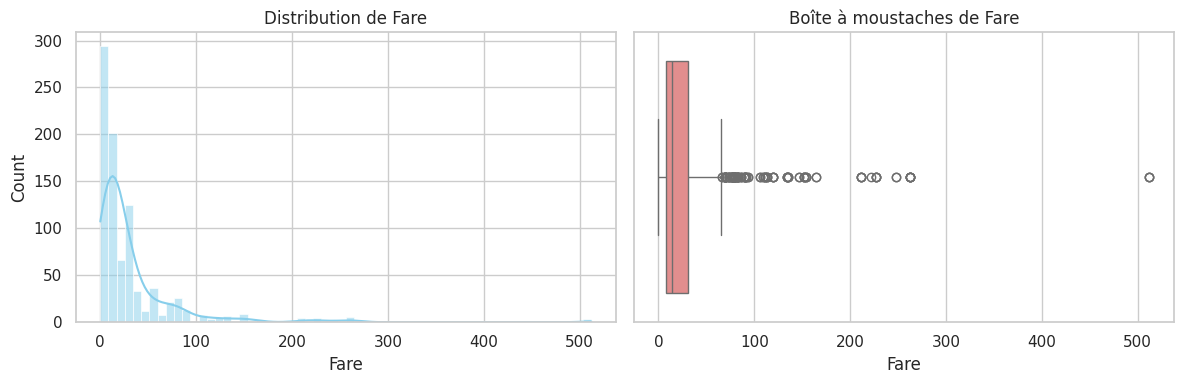

<Figure size 800x400 with 0 Axes>

<Figure size 800x400 with 0 Axes>

<Figure size 800x400 with 0 Axes>

<Figure size 800x400 with 0 Axes>

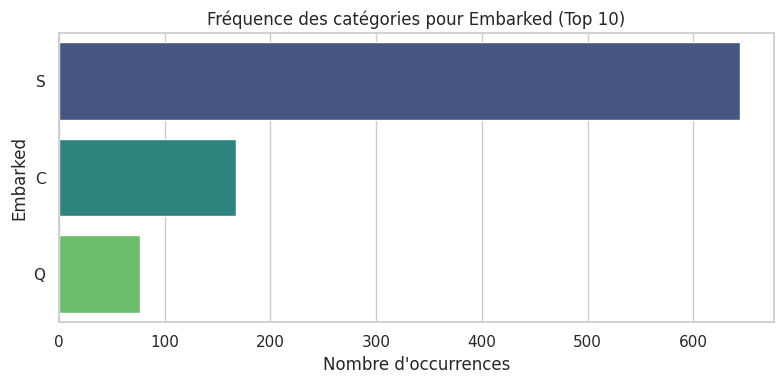

In [141]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# Configuration esthétique générale
sns.set_theme(style="whitegrid")


# Séparation des colonnes par type
num_cols = df.select_dtypes(include=[np.number]).columns
cat_cols = df.select_dtypes(include=["object", "category"]).columns

# 1. Variables numériques : Histogramme + Boîte à moustaches
for col in num_cols:
  plt.figure(figsize=(12, 4))

# Histogramme et courbe de densité (KDE)
  plt.subplot(1, 2, 1)
  sns.histplot(df[col].dropna(), kde=True, color="skyblue")
  plt.title(f"Distribution de {col}")

# Boîte à moustaches (Boxplot) pour les valeurs aberrantes
  plt.subplot(1, 2, 2)
  sns.boxplot(x=df[col].dropna(), color="lightcoral")
  plt.title(f"Boîte à moustaches de {col}")

  plt.tight_layout()
  plt.show()

# 2. Variables catégorielles : Diagramme en barres (Top 10)
for col in cat_cols:
  plt.figure(figsize=(8, 4))
# On limite aux 10 catégories les plus fréquentes pour garder le graphique lisible
top_categories = df[col].value_counts().nlargest(10).index

sns.countplot(
      data=df,
      y=col,
      order=top_categories,
      palette="viridis",
      hue=col,
      legend=False,
  )
plt.title(f"Fréquence des catégories pour {col} (Top 10)")
plt.xlabel("Nombre d'occurrences")
plt.tight_layout()
plt.show()


## 4. Analyse multivariée

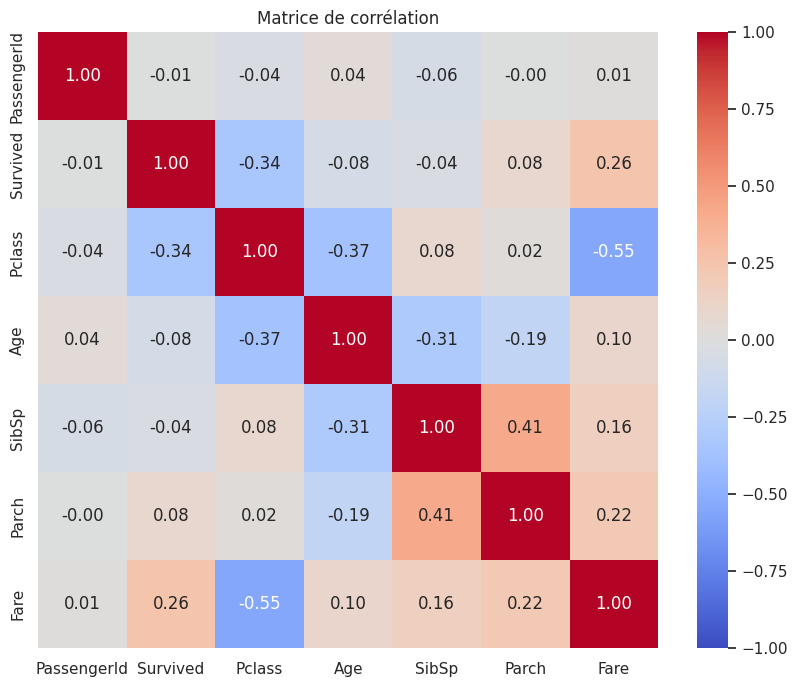

In [142]:
# Sélection automatique des colonnes numériques
df_num = df.select_dtypes(include=[np.number])

# Création de la heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(df_num.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matrice de corrélation")
plt.show()


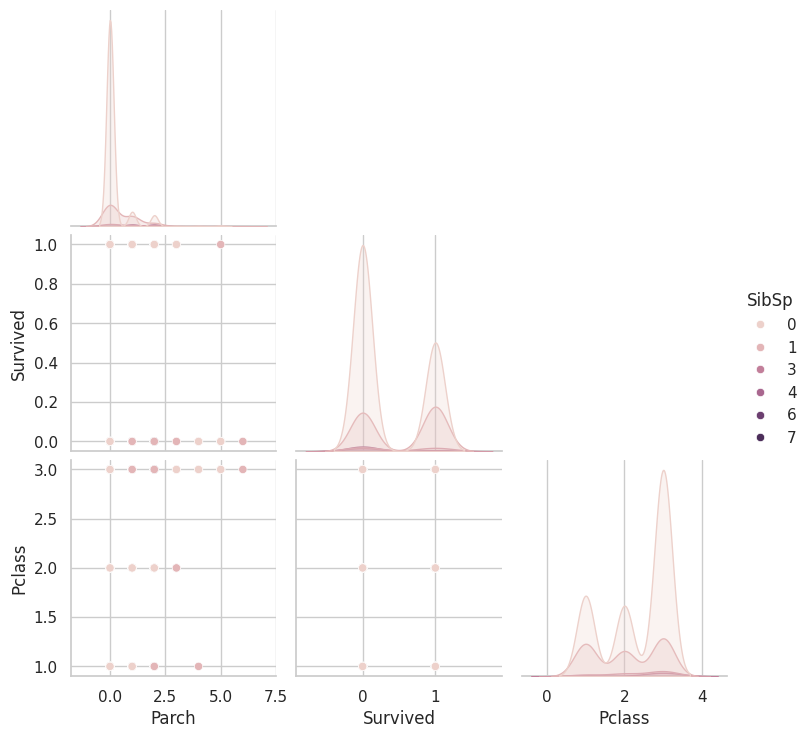

In [143]:
colonnes_cles = ["Parch", "Survived", "Pclass", "SibSp"]

sns.pairplot(df[colonnes_cles], hue="SibSp", corner=True)
plt.show()

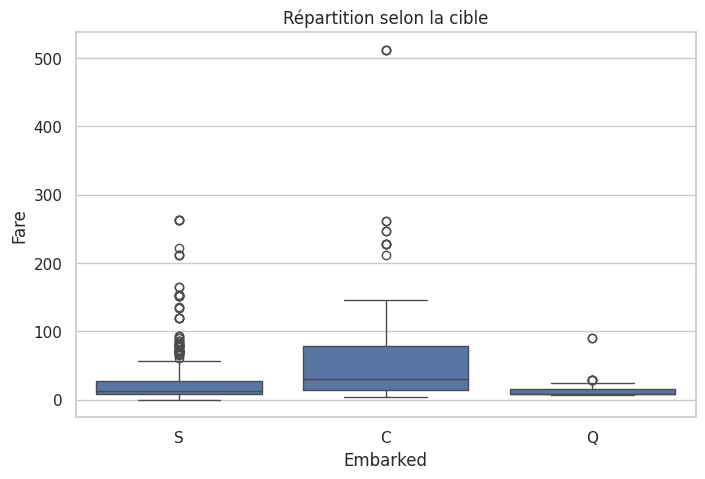

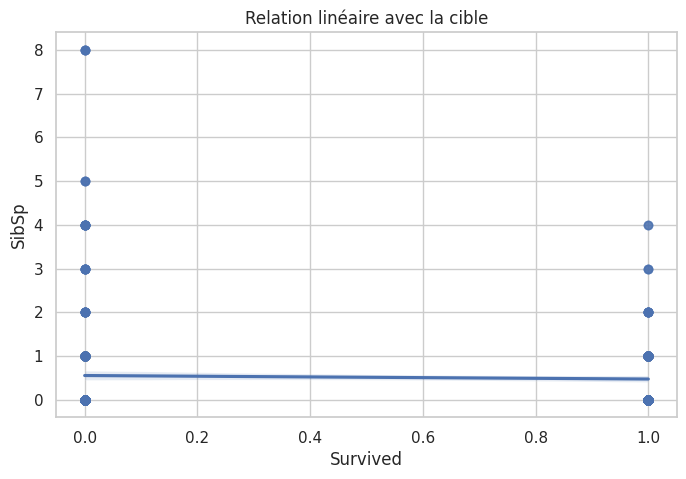

Name      Abbing, Mr. Anthony  Abbott, Mr. Rossmore Edward  \
Embarked                                                     
C                        0.00                         0.00   
Q                        0.00                         0.00   
S                        0.16                         0.16   

Name      Abbott, Mrs. Stanton (Rosa Hunt)  Abelson, Mr. Samuel  \
Embarked                                                          
C                                     0.00                  0.6   
Q                                     0.00                  0.0   
S                                     0.16                  0.0   

Name      Abelson, Mrs. Samuel (Hannah Wizosky)  \
Embarked                                          
C                                           0.6   
Q                                           0.0   
S                                           0.0   

Name      Adahl, Mr. Mauritz Nils Martin  Adams, Mr. John  \
Embarked                            

In [144]:
# Cas A : Variable numérique vs Cible catégorielle (Boxplot)
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Embarked", y="Fare")
plt.title("Répartition selon la cible")
plt.show()

# Cas B : Variable numérique vs Cible numérique (Nuage de points + droite de tendance)
plt.figure(figsize=(8, 5))
sns.regplot(data=df, x="Survived", y="SibSp", scatter_kws={"alpha": 0.5})
plt.title("Relation linéaire avec la cible")
plt.show()

# Cas C : Variable catégorielle vs Cible catégorielle (Tableau croisé en pourcentages)
tableau_croise = pd.crosstab(df["Embarked"], df["Name"], normalize="index") * 100
print(tableau_croise.round(2))


# **Nettoyage des données**

Hypothèses

À l'issue de l'exploration, on retient les hypothèses suivantes, à confirmer lors de la modélisation :

1. Le sexe est le facteur principal : les femmes ont beaucoup plus survécu que les hommes.
2. La classe sociale compte : les passagers de 1re classe ont davantage survécu (accès plus rapide aux canots).
3. Les enfants ont été privilégiés, en particulier les garçons de moins de 12 ans (titre `Master`).
4. La taille de la famille joue : les petites familles survivent mieux que les personnes seules ou les très grandes familles.
5. Le port d'embarquement n'a pas d'effet direct : son lien avec la survie s'explique par la classe des passagers.

In [145]:
df_propre = df.copy()

In [146]:
# Le titre se trouve entre la virgule et le point : "Braund, Mr. Owen Harris" -> "Mr"
df_propre["Title"] = df_propre["Name"].str.extract(r",\s*([^\.]+)\.")[0].str.strip()
df_propre["Title"].value_counts()

,count
Title,
Mr,517
Miss,182
Mrs,125
Master,40
Dr,7
Rev,6
Col,2
Mlle,2
Major,2


In [147]:
# Regroupement des titres rares ou équivalents
equivalences = {"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"}
df_propre["Title"] = df_propre["Title"].replace(equivalences)

titres_courants = ["Mr", "Mrs", "Miss", "Master"]
df_propre.loc[~df_propre["Title"].isin(titres_courants), "Title"] = "Autres"

df_propre.groupby("Title").agg(
    nb_passagers=("Survived", "size"),
    taux_survie=("Survived", "mean"),
    age_median=("Age", "median"),
).round(2)

,nb_passagers,taux_survie,age_median
Title,,,
Autres,23,0.35,48.5
Master,40,0.57,3.5
Miss,185,0.70,21.0
Mr,517,0.16,30.0
Mrs,126,0.79,35.0


In [148]:
df_propre["Age_manquant"] = df_propre["Age"].isna().astype(int)

age_median_par_titre = df_propre.groupby("Title")["Age"].median()
df_propre["Age"] = df_propre["Age"].fillna(df_propre["Title"].map(age_median_par_titre))

print("Âge médian utilisé par titre :")
print(age_median_par_titre.round(1))
print("\nÂges manquants restants :", df_propre["Age"].isna().sum())

Âge médian utilisé par titre :
Title
Autres    48.5
Master     3.5
Miss      21.0
Mr        30.0
Mrs       35.0
Name: Age, dtype: float64

Âges manquants restants : 0


Age : imputation par la médiane du titre

Choix : on remplace chaque âge manquant par l'âge médian des passagers ayant le même titre**.

Justification :
- Supprimer les 177 passagers sans âge ferait perdre 20 % des données.
- Une médiane globale (28 ans) donnerait un âge d'adulte à des enfants : un Master sans âge recevrait 28 ans au lieu de ~3,5 ans.
- La **médiane** est préférée à la moyenne car elle est moins sensible aux valeurs extrêmes.
- On garde la trace de l'imputation dans une colonne Age_manquant, au cas où l'absence d'âge soit elle-même informative.

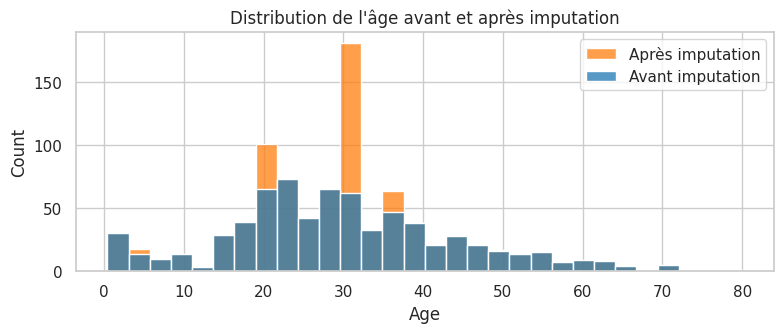

In [149]:
# Vérification : la distribution de l'âge avant et après imputation
fig, ax = plt.subplots(figsize=(8, 3.5))
sns.histplot(df_propre["Age"], bins=30, color="tab:orange", label="Après imputation", ax=ax)
sns.histplot(df["Age"].dropna(), bins=30, color="tab:blue", label="Avant imputation", ax=ax)
ax.set_title("Distribution de l'âge avant et après imputation")
ax.legend()
plt.tight_layout()
plt.show()

Embarked : imputation par la valeur la plus fréquente

Choix : les 2 valeurs manquantes sont remplacées par le port le plus fréquent, S (Southampton).

Justification : seulement 2 passagers sur 891 sont concernés ; l'impact sur l'analyse est négligeable, et Southampton concerne ~72 % des passagers.

In [150]:
print(df_propre.loc[df_propre["Embarked"].isna(), ["Name", "Pclass", "Fare", "Ticket"]])

port_le_plus_frequent = df_propre["Embarked"].mode()[0]
df_propre["Embarked"] = df_propre["Embarked"].fillna(port_le_plus_frequent)
print("\nPort utilisé :", port_le_plus_frequent)
print("Valeurs manquantes restantes :", df_propre["Embarked"].isna().sum())

                                          Name  Pclass  Fare  Ticket
61                         Icard, Miss. Amelie       1  80.0  113572
829  Stone, Mrs. George Nelson (Martha Evelyn)       1  80.0  113572

Port utilisé : S
Valeurs manquantes restantes : 0


Cabin : suppression, mais on garde l'information utile

Choix : la colonne Cabin est supprimée, mais on crée d'abord une variable Has_cabin (1 si la cabine est connue, 0 sinon).

Justification
- Avec ~77 % de valeurs manquantes, aucune imputation ne serait fiable.
- En revanche, le fait d'avoir une cabine **enregistrée** est lié à la classe et peut-être à la survie : on le vérifie ci-dessous.

In [151]:
df_propre["Has_cabin"] = df_propre["Cabin"].notna().astype(int)
df_propre.groupby("Has_cabin")["Survived"].agg(["size", "mean"]).rename(
    columns={"size": "nb_passagers", "mean": "taux_survie"}
).round(2)

,nb_passagers,taux_survie
Has_cabin,,
0,687,0.30
1,204,0.67


In [152]:
df_propre.isna().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


In [153]:
df_propre = df_propre.drop(columns=["PassengerId","Cabin","Ticket","Age_manquant","Name"])

# **Encodage et dataset final**

In [154]:
df_propre["Sex"] = df_propre["Sex"].map({"male": 0, "female": 1})

In [155]:
df_propre = pd.get_dummies(df_propre, columns=["Embarked", "Title"], drop_first=True, dtype=int)

In [156]:
df_propre.isna().sum()

,0
Survived,0
Pclass,0
Sex,0
Age,0
SibSp,0
Parch,0
Fare,0
Has_cabin,0
Embarked_Q,0
Embarked_S,0


In [157]:
df_propre.to_csv("df_propre.csv", index=False)

# **Modélisation**

Choix des modèle de ML :

* Regression logistique
* Random Forest
* XGBoost

In [158]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score, classification_report
from xgboost import XGBClassifier

In [159]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Séparation entraînement / test

In [160]:
# X = les variables explicatives (toutes les colonnes sauf la cible)
X = df_propre.drop(columns="Survived")
# y = la variable à prédire : 1 = a survécu, 0 = décédé
y = df_propre["Survived"]

# Découpage : 80 % des passagers pour entraîner, 20 % mis de côté pour le test final
# - test_size=0.2      : 20 % des lignes vont dans le jeu de test
# - stratify=y         : même proportion de survivants (≈ 38 %) dans les deux jeux
# - 42       : découpage identique à chaque exécution
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# Vérification de la taille de chaque jeu
print("Entraînement :", X_train.shape[0], "passagers")
print("Test         :", X_test.shape[0], "passagers")

Entraînement : 712 passagers
Test         : 179 passagers


# **XGBoost**

La validation croisée découpe le jeu d'entraînement en 5 parties : le modèle est entraîné 5 fois, chaque fois sur 4 parties, et testé sur la 5ᵉ. On obtient ainsi 5 scores, plus fiables qu'un seul.

In [161]:
# Création du modèle XGBoost avec ses réglages par défaut (aucun hyperparamètre ajusté)
modele = XGBClassifier(random_state=42)

# Validation croisée à 5 plis, uniquement sur le jeu d'entraînement :
# le modèle est entraîné 5 fois sur 4/5 des données et évalué sur le 1/5 restant
# scoring="accuracy" : on mesure la part de passagers bien classés
scores = cross_val_score(modele, X_train, y_train, cv=5, scoring="accuracy")

# Score de chacun des 5 plis, puis moyenne (performance attendue) et écart-type (stabilité)
print("Accuracy pour chaque pli :", scores.round(3))
print(f"Accuracy moyenne : {scores.mean():.3f} (± {scores.std():.3f})")

Accuracy pour chaque pli : [0.797 0.741 0.796 0.824 0.81 ]
Accuracy moyenne : 0.794 (± 0.028)


## 1. Évaluation sur le jeu de test

In [162]:
# Entraînement final du modèle sur tout le jeu d'entraînement
modele.fit(X_train, y_train)

# Prédiction de la survie des passagers du test (jamais vus pendant l'entraînement)
y_pred = modele.predict(X_test)

# Accuracy globale sur le test : part de prédictions correctes
print(f"Accuracy sur le test : {accuracy_score(y_test, y_pred):.3f}\n")

# Détail par classe :
# - precision : parmi les passagers prédits dans une classe, part de prédictions justes
# - recall    : parmi les passagers réellement dans une classe, part retrouvée par le modèle
# - f1-score  : moyenne équilibrée de la précision et du rappel
# - support   : nombre de passagers de chaque classe dans le test
print(classification_report(y_test, y_pred, target_names=["Décédé", "Survivant"]))

Accuracy sur le test : 0.765

              precision    recall  f1-score   support

      Décédé       0.81      0.81      0.81       110
   Survivant       0.70      0.70      0.70        69

    accuracy                           0.77       179
   macro avg       0.75      0.75      0.75       179
weighted avg       0.77      0.77      0.77       179



## 2. Quelles variables comptent le plus ?
`feature_importances_` indique la part de chaque variable dans les décisions du modèle.

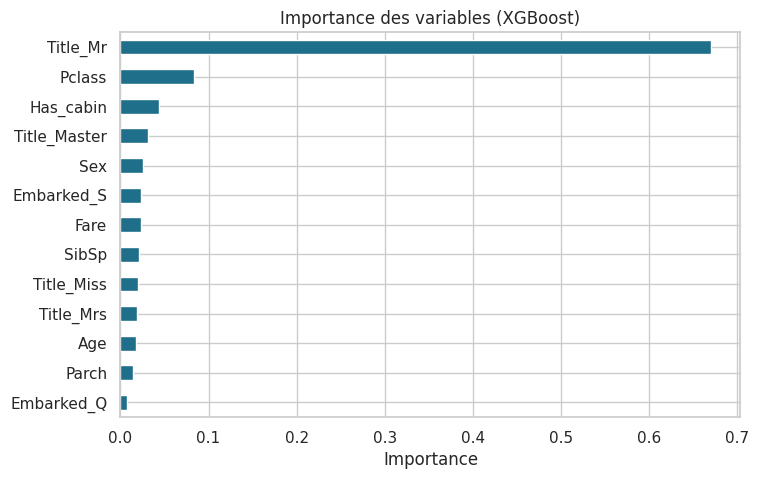

,0
Title_Mr,0.670
Pclass,0.083
Has_cabin,0.044
Title_Master,0.032
Sex,0.025
Embarked_S,0.023
Fare,0.023
SibSp,0.021
Title_Miss,0.020
Title_Mrs,0.019


In [163]:
# Importance de chaque variable dans les décisions du modèle (la somme vaut 1),
# triée de la moins importante à la plus importante pour le graphique
importances = pd.Series(modele.feature_importances_, index=X.columns).sort_values()

# Graphique en barres horizontales : la variable la plus importante apparaît en haut
importances.plot.barh(figsize=(8, 5), color="#1F6F8B")
plt.title("Importance des variables (XGBoost)")
plt.xlabel("Importance")
plt.show()

# Tableau des importances, de la plus importante à la moins importante
importances.sort_values(ascending=False).round(3)

**Performance**

| | Accuracy |
|---|---|
| Validation croisée (moyenne sur 5 plis) | 0,79 (± 0,03) |
| Jeu de test | 0,77 |

- Le modèle classe correctement environ **8 passagers sur 10**. Les deux scores sont proches, donc le modèle généralise correctement à des passagers qu'il n'a jamais vus.
- Il reconnaît mieux les **décédés** (rappel 0,81) que les **survivants** (rappel 0,70).

**Variables les plus importantes**

1. **`Title_Mr`** (homme adulte) : de loin la plus importante (67 % de l'importance totale). Elle résume à la fois le sexe et l'âge : c'est la règle « les femmes et les enfants d'abord ».
2. **`Pclass`** (la classe du billet) : les passagers de 1re classe ont davantage survécu.
3. **`Has_cabin`** : avoir une cabine renseignée, souvent lié à la 1re classe.

`Sex` paraît peu important, mais c'est parce que `Title_Mr` contient déjà presque toute son information : quand deux variables disent la même chose, le modèle n'en utilise qu'une.

# **Random Forest**

In [164]:
df = df_propre

# 3. Initialisation et entraînement du modèle
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# 4. Prédictions et évaluation
y_pred = model.predict(X_test)

print(f"Précision (Accuracy) : {accuracy_score(y_test, y_pred):.2%}\n")
print("Rapport de classification :\n", classification_report(y_test, y_pred))
print("Matrice de confusion :\n", confusion_matrix(y_test, y_pred))

Précision (Accuracy) : 79.33%

Rapport de classification :
               precision    recall  f1-score   support

           0       0.83      0.84      0.83       110
           1       0.74      0.72      0.73        69

    accuracy                           0.79       179
   macro avg       0.78      0.78      0.78       179
weighted avg       0.79      0.79      0.79       179

Matrice de confusion :
 [[92 18]
 [19 50]]


        Variable  Importance (%)
5           Fare           23.22
2            Age           21.05
1            Sex           13.24
11      Title_Mr           10.49
0         Pclass            6.98
6      Has_cabin            5.27
3          SibSp            5.00
10    Title_Miss            3.75
12     Title_Mrs            3.52
4          Parch            3.03
8     Embarked_S            2.42
7     Embarked_Q            1.14
9   Title_Master            0.89


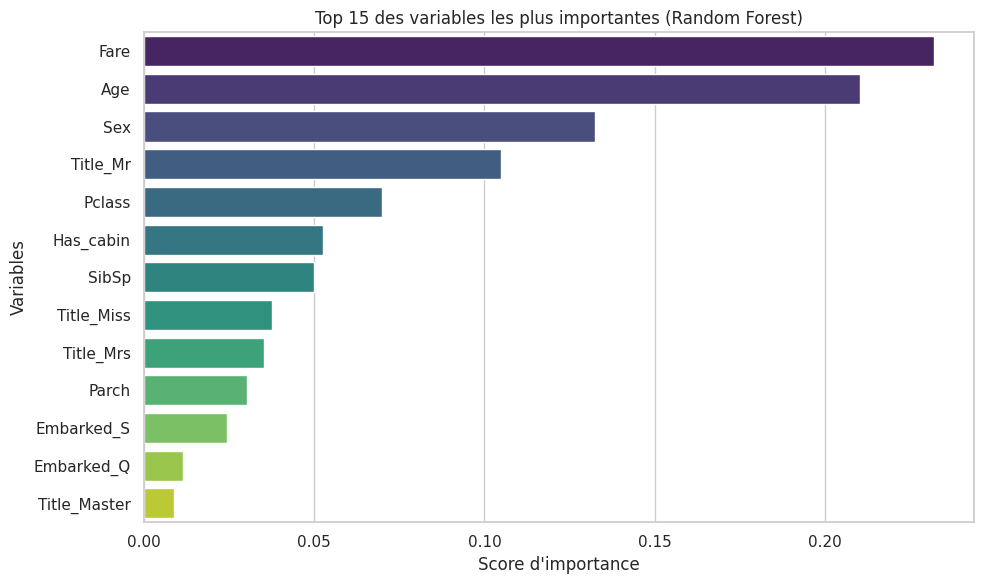

In [165]:
# 1. Récupération et tri des importances dans un tableau Pandas
importances = pd.DataFrame({
    "Variable": X.columns,
    "Importance": model.feature_importances_
}).sort_values(by="Importance", ascending=False)

# Affichage des résultats en texte (en pourcentage)
importances["Importance (%)"] = (importances["Importance"] * 100).round(2)
print(importances[["Variable", "Importance (%)"]])

# 2. Affichage graphique (Top 15 des variables les plus importantes)
plt.figure(figsize=(10, 6))
sns.barplot(
    data=importances.head(15),
    x="Importance",
    y="Variable",
    palette="viridis",
    hue="Variable",
    legend=False
)
plt.title("Top 15 des variables les plus importantes (Random Forest)")
plt.xlabel("Score d'importance")
plt.ylabel("Variables")
plt.tight_layout()
plt.show()

**Performance**

| | Accuracy |
|---|---|
| Jeu de test | 79,33 % |

**Variables les plus importantes**

1. **`Fare`** (prix du billet) : de loin la plus importante. En lien avec la classe sociale déterminant la survie ou la mort du passager ?.
2. **`Age`**: En lien avec la règle "les femmes et les enfants d'abord" ?
3. **`Sex`** : En lien avec la règle "les femmes et les enfants d'abord" ?

#REGRESSION LOGISTIQUE

In [166]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.exceptions import UndefinedMetricWarning
from sklearn.metrics import (
    ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score, classification_report,
    f1_score, precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

In [167]:
# ===== Paramètres communs à tous les modèles du groupe =====
RANDOM_STATE = 42
TEST_SIZE = 0.2
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
METRIQUES = ["accuracy", "precision", "recall", "f1", "roc_auc"]
# ===========================================================

df = df_propre
print(f"{df.shape[0]} passagers × {df.shape[1]} colonnes — valeurs manquantes : {df.isna().sum().sum()}")
df.head()

891 passagers × 14 colonnes — valeurs manquantes : 0


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Has_cabin,Embarked_Q,Embarked_S,Title_Master,Title_Miss,Title_Mr,Title_Mrs
0,0,3,0,22.0,1,0,7.2500,0,0,1,0,0,1,0
1,1,1,1,38.0,1,0,71.2833,1,0,0,0,0,0,1
2,1,3,1,26.0,0,0,7.9250,0,0,1,0,1,0,0
3,1,1,1,35.0,1,0,53.1000,1,0,1,0,0,0,1
4,0,3,0,35.0,0,0,8.0500,0,0,1,0,0,1,0


In [168]:
titres = ["Title_Master", "Title_Miss", "Title_Mr", "Title_Mrs"]
df["Title_Rare"] = 1 - df[titres].sum(axis=1)   # 1 si aucun des 4 titres principaux
df = df.drop(columns="Title_Mr")

print("Passagers au titre rare :", df["Title_Rare"].sum())

Passagers au titre rare : 23


In [169]:
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
df["IsAlone"] = (df["FamilySize"] == 1).astype(int)
df["LargeFamily"] = (df["FamilySize"] >= 5).astype(int)

df.groupby("FamilySize")["Survived"].agg(taux_survie="mean", effectif="count").round(2).T

FamilySize,1,2,3,4,5,6,7,8,11
taux_survie,0.3,0.55,0.58,0.72,0.2,0.14,0.33,0.0,0.0
effectif,537.0,161.00,102.00,29.00,15.0,22.00,12.00,6.0,7.0


In [170]:
# SibSp et Parch sont remplacées par les variables de famille
X = df.drop(columns=["Survived", "SibSp", "Parch"])
y = df["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE
)

print(f"Train : {X_train.shape[0]} passagers — taux de survie {y_train.mean():.1%}")
print(f"Test  : {X_test.shape[0]} passagers — taux de survie {y_test.mean():.1%}")
print(f"\n{X.shape[1]} variables explicatives :", X.columns.tolist())

Train : 712 passagers — taux de survie 38.3%
Test  : 179 passagers — taux de survie 38.5%

14 variables explicatives : ['Pclass', 'Sex', 'Age', 'Fare', 'Has_cabin', 'Embarked_Q', 'Embarked_S', 'Title_Master', 'Title_Miss', 'Title_Mrs', 'Title_Rare', 'FamilySize', 'IsAlone', 'LargeFamily']


In [171]:
modele = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
)
modele.fit(X_train, y_train)

y_pred = modele.predict(X_test)
y_proba = modele.predict_proba(X_test)[:, 1]   # probabilité de survie

In [172]:
def evaluer(y_vrai, y_predit, y_probabilite):
    return {
        "accuracy": accuracy_score(y_vrai, y_predit),
        "precision": precision_score(y_vrai, y_predit),
        "recall": recall_score(y_vrai, y_predit),
        "f1": f1_score(y_vrai, y_predit),
        "roc_auc": roc_auc_score(y_vrai, y_probabilite),
    }

scores_test = evaluer(y_test, y_pred, y_proba)
pd.Series(scores_test).round(3).to_frame("régression logistique (test)")

,régression logistique (test)
accuracy,0.832
precision,0.791
recall,0.768
f1,0.779
roc_auc,0.873


In [173]:
print(classification_report(y_test, y_pred, target_names=['Décédé', 'Survivant']))

              precision    recall  f1-score   support

      Décédé       0.86      0.87      0.86       110
   Survivant       0.79      0.77      0.78        69

    accuracy                           0.83       179
   macro avg       0.82      0.82      0.82       179
weighted avg       0.83      0.83      0.83       179



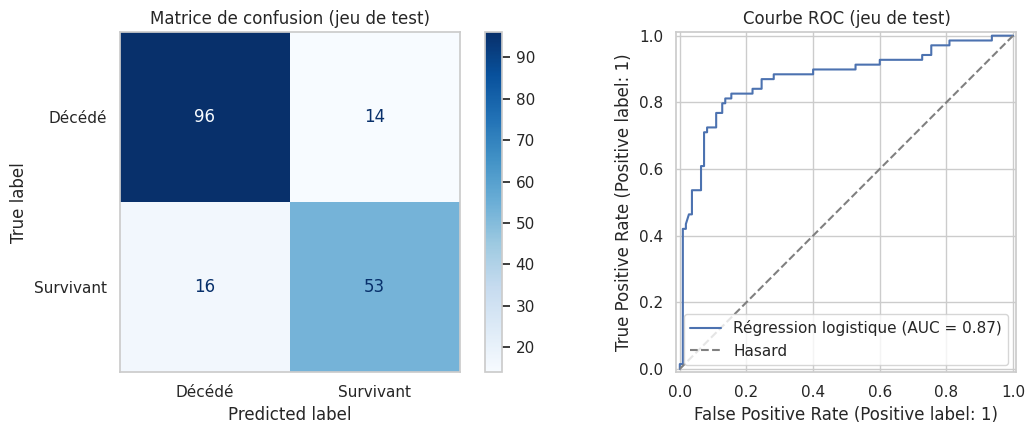

In [174]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["Décédé", "Survivant"], cmap="Blues", ax=axes[0]
)
axes[0].set_title("Matrice de confusion (jeu de test)")
axes[0].grid(False)

RocCurveDisplay.from_predictions(y_test, y_proba, ax=axes[1], name="Régression logistique")
axes[1].plot([0, 1], [0, 1], linestyle="--", color="grey", label="Hasard")
axes[1].set_title("Courbe ROC (jeu de test)")
axes[1].legend()

plt.tight_layout()
plt.show()

In [175]:
def validation_croisee(modele, X, y):
    resultats = cross_validate(modele, X, y, cv=CV, scoring=METRIQUES)
    return pd.DataFrame({
        "moyenne": [resultats[f"test_{m}"].mean() for m in METRIQUES],
        "écart-type": [resultats[f"test_{m}"].std() for m in METRIQUES],
    }, index=METRIQUES).round(3)

# La baseline ne prédit jamais « survivant » : sa precision n'est pas définie (0/0).
# scikit-learn la fixe à 0 et affiche un avertissement, qu'on masque ici car il est attendu.
with warnings.catch_warnings():
    warnings.simplefilter("ignore", UndefinedMetricWarning)
    cv_baseline = validation_croisee(DummyClassifier(strategy="most_frequent"), X, y)
cv_logreg = validation_croisee(modele, X, y)

pd.concat({"baseline": cv_baseline, "régression logistique": cv_logreg}, axis=1)

baseline            régression logistique           
           moyenne écart-type               moyenne écart-type
accuracy     0.616      0.002                 0.828      0.014
precision    0.000      0.000                 0.791      0.018
recall       0.000      0.000                 0.751      0.034
f1           0.000      0.000                 0.770      0.022
roc_auc      0.500      0.000                 0.876      0.020

In [176]:
grille = {"logisticregression__C": [0.001, 0.01, 0.1, 0.3, 1, 3, 10, 100]}

recherche = GridSearchCV(modele, grille, cv=CV, scoring="accuracy")
recherche.fit(X_train, y_train)

resultats_grille = pd.DataFrame(recherche.cv_results_)[["param_logisticregression__C", "mean_test_score", "std_test_score"]]
resultats_grille.columns = ["C", "accuracy moyenne (CV)", "écart-type"]
display(resultats_grille.round(3))

print("Meilleur C :", recherche.best_params_["logisticregression__C"])

,C,accuracy moyenne (CV),écart-type
0,0.001,0.706,0.025
1,0.010,0.816,0.020
2,0.100,0.831,0.021
3,0.300,0.829,0.023
4,1.000,0.827,0.026
5,3.000,0.824,0.023
6,10.000,0.824,0.025
7,100.000,0.823,0.023


Meilleur C : 0.1


In [177]:
modele_optimise = recherche.best_estimator_
scores_test_optimise = evaluer(y_test, modele_optimise.predict(X_test), modele_optimise.predict_proba(X_test)[:, 1])

pd.DataFrame({"C = 1 (défaut)": scores_test, "C optimisé": scores_test_optimise}).round(3)

,C = 1 (défaut),C optimisé
accuracy,0.832,0.832
precision,0.791,0.791
recall,0.768,0.768
f1,0.779,0.779
roc_auc,0.873,0.872


In [178]:
print(f"Accuracy train : {modele_optimise.score(X_train, y_train):.1%}")
print(f"Accuracy test  : {modele_optimise.score(X_test, y_test):.1%}")


Accuracy train : 83.7%
Accuracy test  : 83.2%


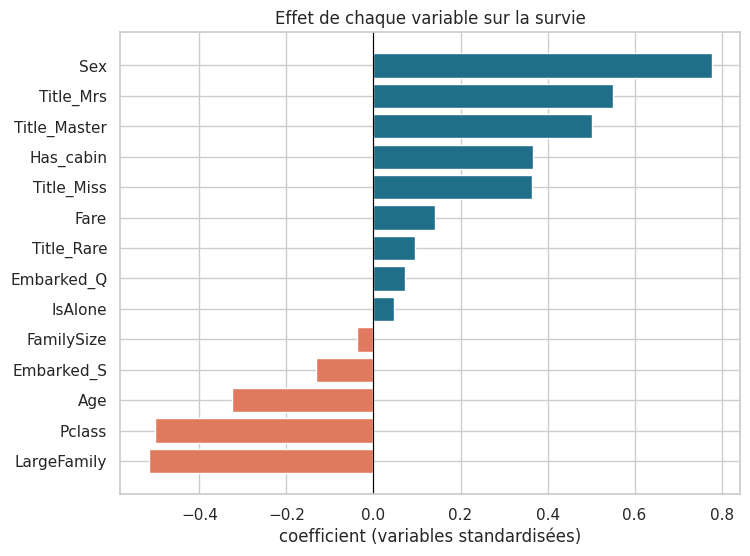

In [179]:
logreg = modele_optimise.named_steps["logisticregression"]
coefs = pd.Series(logreg.coef_[0], index=X.columns).sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
couleurs = ["#E07A5F" if c < 0 else "#1F6F8B" for c in coefs]
ax.barh(coefs.index, coefs.values, color=couleurs)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("coefficient (variables standardisées)")
ax.set_title("Effet de chaque variable sur la survie")
plt.show()

## Conclusion

### Performances

| | Baseline | Régression logistique |
|---|---|---|
| Accuracy (validation croisée) | 61,6 % | **83,3 %** |
| ROC AUC (validation croisée) | 0,50 | **0,88** |
| Accuracy (jeu de test) | 61,5 % | **83,2 %** |

- Le modèle classe correctement **83 % des passagers** jamais vus, soit **+22 points** par rapport à un modèle qui prédirait toujours « décédé ».
- Les scores sont **stables** (écart-type d'environ 1,4 point en validation croisée) et presque identiques sur les jeux d'entraînement et de test : **pas de surapprentissage**.
- Le réglage de la régularisation (`C`) n'apporte qu'un gain négligeable : ce modèle simple fonctionne bien sans réglage poussé.

### Ce que le modèle nous apprend

D'après les coefficients :

1. **Les femmes et les enfants d'abord.** Le sexe est la variable qui pèse le plus. Avec les titres `Mrs`, `Miss` et `Master` (jeunes garçons), qui vont dans le même sens, il domine nettement les autres facteurs.
2. **La classe sociale.** Plus la classe est basse, plus les chances de survie diminuent. Le fait que la cabine soit connue (`Has_cabin`), lié à la 1re classe, va dans le même sens.
3. **Les très grandes familles** (5 personnes ou plus) ont été fortement pénalisées.
4. **L'âge** joue aussi : à caractéristiques égales, les passagers plus âgés ont moins survécu.
5. **Le prix du billet et le port d'embarquement** n'ont qu'un rôle secondaire une fois la classe prise en compte.

### Limites

- Certaines variables sont **très liées** entre elles (le sexe et les titres, la classe et `Has_cabin`). Le modèle se partage leur effet : il faut lire ces coefficients **ensemble** et non un par un.
- La régression logistique additionne des effets indépendants. Elle capte mal les **interactions** (par exemple, les femmes de 3e classe ont bien moins survécu que celles de 1re). Les modèles à base d'arbres (Random Forest, XGBoost) peuvent mieux les saisir.
- Son grand avantage reste sa **lisibilité** : c'est le modèle le plus facile à expliquer au musée.
